# 06 · Persistência, ataques e casos  🔴 *difícil*

Último notebook da série. Juntamos o que vimos para responder perguntas mais "de pesquisa":

1. **Persistência:** por quanto tempo uma origem continua ativa? Como lidar com o que acontece **fora** da janela
   observada (*censura*)?
2. **Backscatter:** quantos **ataques DDoS** os sensores enxergaram, contra quem, por quanto tempo — e com que
   **intensidade** estimada?
3. **Pools:** existem redes /24 cujos IPs **dividem o trabalho** entre os sensores?
4. **Estudos de caso por regra:** como achar, de forma reprodutível, os "personagens" interessantes do dataset?

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A pasta raiz da série (onde estão os .py). Funciona tanto na raiz quanto em solucoes/.
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "solucoes" else os.getcwd()
sys.path.insert(0, RAIZ)
import holoscope_io as hio
import holoscope_ana as ha
ha.estilo()

# >>> Para usar os DADOS REAIS, troque só esta linha pela pasta dos parquet <<<
PASTA = os.path.join(RAIZ, "dados_sinteticos")
if not os.path.isdir(PASTA):   # primeira vez: gera os dados fictícios (~20 s)
    import subprocess
    subprocess.run([sys.executable, os.path.join(RAIZ, "gerar_sintetico_real.py"), "--saida", PASTA], check=True)

In [2]:
df = hio.carregar_holoscope(PASTA, extras=("asn",))
df["flags"] = hio.flags_texto(df["tcp_flags"])
df["backscatter"] = df["flags"].isin(["SA", "R", "RA"])
df["dia"] = df["ts"].dt.floor("D")
scan = ha.adicionar_entidades(df[~df["backscatter"]])
bsc = df[df["backscatter"]].copy()
SENS = sorted(df["sensor"].unique())
DIAS = pd.date_range(df["dia"].min(), df["dia"].max(), freq="D")
print(f"varredura: {len(scan):,} pacotes | backscatter: {len(bsc):,} pacotes | {len(DIAS)} dias")

83 arquivos | 6 sensores (worker) | 2026-09-01 a 2026-09-14 | 2,024,894 pacotes | 67 MB na memória
origens reservadas/privadas descartadas: 35,000


varredura: 1,908,199 pacotes | backscatter: 116,695 pacotes | 14 dias


## 1. Persistência das origens

Para cada IP de varredura: em **quantos dias** esteve ativo, o **primeiro** e o **último** dia, e o **tempo de vida**
(último − primeiro + 1).

In [3]:
vida = scan.groupby("ent_ip").agg(primeiro=("dia", "min"), ultimo=("dia", "max"), dias_ativos=("dia", "nunique"),
                                  sensores=("sensor", "nunique"), pacotes=("ts", "size"))
vida["vida_dias"] = (vida["ultimo"] - vida["primeiro"]).dt.days + 1
tab = vida["dias_ativos"].value_counts().sort_index().to_frame("IPs")
tab["%"] = (tab["IPs"] / tab["IPs"].sum() * 100).round(1)
tab.T

dias_ativos,1,2,3,4,5,6,7,8,9,10,11,12,13,14
IPs,21580.0,3040.0,2415.0,2414.0,2502.0,1521.0,1472.0,283.0,269.0,82.0,57.0,38.0,13.0,6.0
%,60.5,8.5,6.8,6.8,7.0,4.3,4.1,0.8,0.8,0.2,0.2,0.1,0.0,0.0


### Censura: o que não vemos

Um IP visto **no último dia** pode continuar ativo depois — não sabemos quando ele "morre". Dizemos que sua vida
está **censurada à direita**. Se simplesmente tirarmos a média de `vida_dias`, vamos **subestimar** as vidas longas.

O estimador de **Kaplan–Meier** resolve isso: em cada instante, usa só quem ainda estava "em risco", tratando os
censurados como "sobreviveram pelo menos até aqui". O resultado é a curva $S(t) = P(\text{vida} > t)$.

(Há também censura **à esquerda** — IPs vistos no **primeiro** dia podem ter começado antes. Aqui a ignoramos
por simplicidade; veja os desafios.)

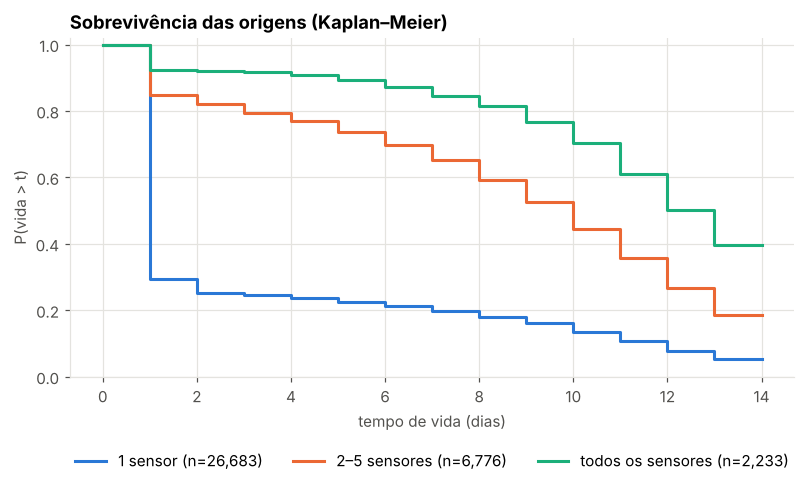

16.5% dos IPs estão censurados (vistos no último dia)


In [4]:
vida["censurado"] = vida["ultimo"] == DIAS[-1]
vida["grupo"] = pd.cut(vida["sensores"], [0, 1, len(SENS) - 1, len(SENS)],
                       labels=["1 sensor", f"2–{len(SENS)-1} sensores", "todos os sensores"])
fig, ax = plt.subplots(figsize=(8.5, 4))
for k, (g, sub) in enumerate(vida.groupby("grupo", observed=True)):
    S = ha.kaplan_meier(sub["vida_dias"], ~sub["censurado"])
    ax.step(S.index, S.values, where="post", color=ha.PALETA[k], label=f"{g} (n={len(sub):,})")
ax.set_xlabel("tempo de vida (dias)"); ax.set_ylabel("P(vida > t)"); ax.set_ylim(0, 1.02)
ax.set_title("Sobrevivência das origens (Kaplan–Meier)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.show()
print(f"{vida['censurado'].mean():.1%} dos IPs estão censurados (vistos no último dia)")

**Leitura:** quem é visto em **todos** os sensores vive muito mais — são varredores persistentes. Quem aparece em
um sensor só costuma sumir no mesmo dia.

### ✏️ TODO 1 — Quanto a censura engana?

Compare duas estimativas da **probabilidade de um IP viver mais de 7 dias**:

* **ingênua:** fração de IPs com `vida_dias > 7` (ignorando censura);
* **Kaplan–Meier:** $S(7)$ da curva com todos os IPs.

Guarde em `resp_1 = (ingenua, km)`. Qual é maior? Por quê?

<details><summary><b>Dica</b> (clique)</summary>

`S = ha.kaplan_meier(vida["vida_dias"], ~vida["censurado"])`; o valor em 7 é `S[S.index <= 7].iloc[-1]`.

</details>

In [5]:
resp_1 = None   # TODO

In [6]:
# Verificação (não precisa mexer)
if resp_1 is None:
    print("⏳ TODO 1 ainda não resolvido")
else:
    assert all(0 < x < 1 for x in resp_1)
    assert resp_1[1] >= resp_1[0], "o KM corrige a subestimação: deveria ser maior ou igual"
    print("✅ TODO 1 ok")

⏳ TODO 1 ainda não resolvido


## 2. Backscatter: enxergando ataques DDoS

Num ataque **SYN flood** com origens forjadas aleatoriamente, a vítima responde (SYN-ACK ou RST) para endereços
espalhados por **toda** a internet. Uma darknet que monitora $N$ endereços recebe, em média, uma fração
$N / 2^{32}$ dessas respostas. Daí a ideia clássica (Moore et al., 2001):

$$ \text{taxa estimada do ataque} \approx \frac{\text{pacotes de backscatter observados}}{\text{duração}} \times \frac{2^{32}}{N} $$

Aqui a **origem** do pacote é a **vítima**. Primeiro, um resumo por vítima:

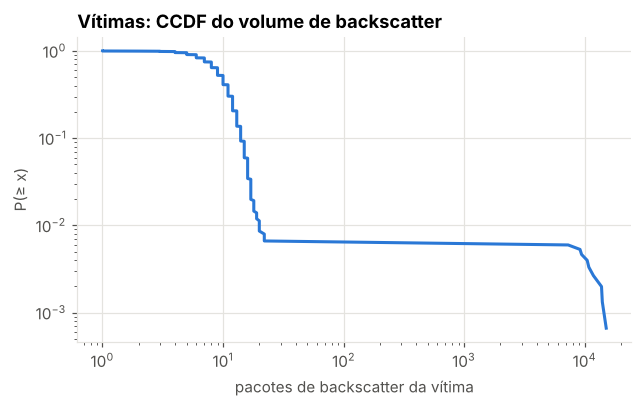

,pacotes,sensores,inicio,fim,porta,asn_org,duracao_min,vitima
src_ip,,,,,,,,
863961533,15102,6,2026-09-13 01:54:27.783615273+00:00,2026-09-13 02:32:09.298738986+00:00,53,Hosting Exemplo 111 (UA),37.691919,51.127.1.189
1089942418,14015,6,2026-09-10 23:39:38.522600783+00:00,2026-09-11 00:11:52.363484917+00:00,80,Hosting Exemplo 179 (CN),32.230681,64.247.51.146
472717246,13800,6,2026-09-05 08:35:31.461115704+00:00,2026-09-05 09:47:04.541245206+00:00,443,Cloud Exemplo 285 (US),71.551335,28.45.23.190
2786595810,11832,6,2026-09-02 10:46:41.021175379+00:00,2026-09-02 11:34:27.022649972+00:00,53,Cloud Exemplo 006 (CN),47.766691,166.24.19.226
3641387773,10836,6,2026-09-14 17:50:56.736366601+00:00,2026-09-14 18:44:56.104509598+00:00,53,Hosting Exemplo 230 (US),53.989469,217.11.42.253
3311341144,10494,6,2026-09-05 14:46:57.626272117+00:00,2026-09-05 16:14:48.333466487+00:00,443,Hosting Exemplo 134 (ID),87.845120,197.95.14.88
1650138079,9432,6,2026-09-14 18:01:09.231612681+00:00,2026-09-14 18:56:59.679464555+00:00,22,Hosting Exemplo 329 (US),55.840798,98.91.27.223
1179845201,9150,6,2026-09-10 01:37:48.054603566+00:00,2026-09-10 01:58:51.619111901+00:00,22,Hosting Exemplo 213 (IN),21.059408,70.83.2.81
1917977523,7296,6,2026-09-09 19:41:51.961453335+00:00,2026-09-09 20:43:32.641019228+00:00,443,Hosting Exemplo 371 (CN),61.677993,114.82.3.179


In [7]:
vit = bsc.groupby("src_ip").agg(pacotes=("ts", "size"), sensores=("sensor", "nunique"),
                                inicio=("ts", "min"), fim=("ts", "max"),
                                porta=("src_port", lambda s: s.mode()[0]), asn_org=("asn_org", "first"))
vit["duracao_min"] = (vit["fim"] - vit["inicio"]).dt.total_seconds() / 60
vit = vit.sort_values("pacotes", ascending=False)
x, y = ha.ccdf(vit["pacotes"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.loglog(x, y, color=ha.PALETA[0]); ax.set_xlabel("pacotes de backscatter da vítima")
ax.set_ylabel("P(≥ x)"); ax.set_title("Vítimas: CCDF do volume de backscatter"); plt.show()
vit.head(12).assign(vitima=lambda t: hio.ip_texto(pd.Series(t.index, index=t.index)))

A maioria das "vítimas" tem **pouquíssimos** pacotes, espalhados no tempo (ruído de fundo: conexões
recusadas, ataques pequenos). Poucas têm milhares de pacotes, concentrados em minutos, vistos por **todos** os
sensores — esses são os **episódios de ataque**.

### ✏️ TODO 2 — Listar os episódios de ataque

Defina um **episódio** como uma vítima com **≥ 1000 pacotes** de backscatter e vista em **≥ 5 sensores**.
Guarde em `resp_2` o `DataFrame` dos episódios (a partir de `vit`), ordenado pelo início. Desenhe uma "linha do
tempo": um segmento horizontal por episódio, do início ao fim.

<details><summary><b>Dica</b> (clique)</summary>

`vit[(vit["pacotes"] >= 1000) & (vit["sensores"] >= 5)].sort_values("inicio")`; para o gráfico,
`ax.hlines(y, inicio, fim)`.

</details>

In [8]:
resp_2 = None   # TODO

In [9]:
# Verificação (não precisa mexer)
if resp_2 is None:
    print("⏳ TODO 2 ainda não resolvido")
else:
    assert (resp_2["pacotes"] >= 1000).all() and (resp_2["sensores"] >= 5).all()
    assert 3 <= len(resp_2) <= 30
    print("✅ TODO 2 ok —", len(resp_2), "episódios")

⏳ TODO 2 ainda não resolvido


### Estimando a intensidade

Quantos endereços os sensores monitoram ($N$)? Sem a lista oficial, estimamos pelo nº de **endereços de destino
distintos** observados (uma darknet ativa recebe pacotes em praticamente todos os seus endereços).

In [10]:
N = df["dst_ip"].nunique()
fator = 2**32 / N
print(f"N ≈ {N:,} endereços monitorados → cada pacote observado representa ≈ {fator:,.0f} pacotes na internet")

maior = vit.iloc[0]
pps_obs = maior["pacotes"] / max(maior["duracao_min"] * 60, 1)
print(f"Maior vítima: {hio.ip_texto(pd.Series([vit.index[0]])).iloc[0]} ({maior['asn_org']}), porta {maior['porta']}")
print(f"  {maior['pacotes']:,} pacotes em {maior['duracao_min']:.0f} min → {pps_obs:.2f} pacotes/s observados")
print(f"  intensidade estimada das RESPOSTAS da vítima ≈ {pps_obs * fator:,.0f} pacotes/s")

N ≈ 1,524 endereços monitorados → cada pacote observado representa ≈ 2,818,220 pacotes na internet
Maior vítima: 51.127.1.189 (Hosting Exemplo 111 (UA)), porta 53
  15,102 pacotes em 38 min → 6.68 pacotes/s observados
  intensidade estimada das RESPOSTAS da vítima ≈ 18,819,577 pacotes/s


> ⚠️ **Limitações:** a estimativa supõe que o atacante sorteia endereços de origem **uniformemente** em todo o
> espaço IPv4, que a vítima responde a **todos** os SYN e que nada se perde no caminho. Com só ~1.500 endereços
> monitorados, o fator de extrapolação é enorme (milhões) e o erro também. Telescópios grandes (um /8 tem
> 16 milhões de endereços) dão estimativas muito melhores.

### ✏️ TODO 3 — Intensidade de todos os episódios

Acrescente a `resp_2` (ou a uma cópia) as colunas `pps_observado` e `pps_estimado` e guarde o resultado em
`resp_3`. Qual episódio foi o mais intenso? Ele é também o mais longo?

<details><summary><b>Dica</b> (clique)</summary>

`pps_observado = pacotes / (duracao_min * 60)`; `pps_estimado = pps_observado * fator`.
Se o TODO 2 não foi feito, crie os episódios primeiro.

</details>

In [11]:
resp_3 = None   # TODO

In [12]:
# Verificação (não precisa mexer)
if resp_3 is None:
    print("⏳ TODO 3 ainda não resolvido")
else:
    assert {"pps_observado", "pps_estimado"} <= set(resp_3.columns) and (resp_3["pps_estimado"] > 0).all()
    print("✅ TODO 3 ok")

⏳ TODO 3 ainda não resolvido


## 3. "Pools": redes que dividem o trabalho

No notebook 02, o modelo nulo mostrou que agregar IP → /24 aumenta a cobertura quase só por efeito mecânico.
Mas pode haver **algumas** redes em que vários IPs **dividem** a tarefa: cada IP varre **um** sensor, e juntos
cobrem vários. Uma regra para achá-las:

* a /24 tem **≥ 5 IPs** ativos;
* **cada** IP aparece em **um único** sensor;
* a /24, somando os IPs, cobre **≥ 3 sensores**;
* a atividade é **sincronizada**: todos os IPs da /24 agem dentro de uma janela de **≤ 3 dias**.

A última condição é crucial: sem ela, IPs da mesma rede ativos em semanas diferentes (coincidência) entrariam.

In [13]:
por_ip = scan.groupby("ent_ip").agg(rede=("ent_24", "first"), n_sens=("sensor", "nunique"),
                                    t0=("ts", "min"), t1=("ts", "max"))
por_rede = por_ip.groupby("rede").agg(ips=("n_sens", "size"), todos_1_sensor=("n_sens", lambda s: (s == 1).all()),
                                      t0=("t0", "min"), t1=("t1", "max"))
sens_rede = scan.groupby("ent_24")["sensor"].nunique()
por_rede["sensores"] = sens_rede.reindex(por_rede.index)
por_rede["janela_dias"] = (por_rede["t1"] - por_rede["t0"]).dt.total_seconds() / 86400

sem_sinc = por_rede[(por_rede["ips"] >= 5) & por_rede["todos_1_sensor"] & (por_rede["sensores"] >= 3)]
pools = sem_sinc[sem_sinc["janela_dias"] <= 3]
print(f"candidatas SEM exigir sincronia: {len(sem_sinc)} | COM sincronia (≤ 3 dias): {len(pools)}")
pools.sort_values("ips", ascending=False).head(8).set_axis(ha.rotulo("/24", pools.sort_values(
    "ips", ascending=False).head(8).index), axis=0)

candidatas SEM exigir sincronia: 231 | COM sincronia (≤ 3 dias): 58


,ips,todos_1_sensor,t0,t1,sensores,janela_dias
97.115.90.0/24,19,True,2026-09-02 01:51:52.254964525+00:00,2026-09-03 23:15:31.097528763+00:00,6,1.891422
53.228.83.0/24,19,True,2026-09-10 01:09:52.819072869+00:00,2026-09-11 22:31:14.287632234+00:00,6,1.889832
184.57.106.0/24,19,True,2026-09-03 02:22:23.782314999+00:00,2026-09-04 23:45:42.794607747+00:00,6,1.891192
195.235.67.0/24,19,True,2026-09-05 01:06:23.979604784+00:00,2026-09-06 21:30:47.349765476+00:00,5,1.850270
180.93.97.0/24,19,True,2026-09-08 01:08:38.042781043+00:00,2026-09-09 23:26:02.411961026+00:00,6,1.928754
135.67.100.0/24,19,True,2026-09-10 01:02:08.881019281+00:00,2026-09-11 23:58:05.439637464+00:00,6,1.955516
72.19.107.0/24,18,True,2026-09-09 01:06:48.513464055+00:00,2026-09-10 23:00:56.049633277+00:00,5,1.912587
116.153.106.0/24,18,True,2026-09-03 01:41:10.782553387+00:00,2026-09-04 23:55:41.361119074+00:00,6,1.926743


Um "pool" deveria ser **homogêneo**: mesma porta, mesma janela de dias. Vejamos o primeiro:

In [14]:
rede = pools.sort_values("ips", ascending=False).index[0]
caso = scan[scan["ent_24"] == rede]
print("rede", ha.rotulo("/24", [rede]).iloc[0], "|", caso["asn_org"].iloc[0])
caso.groupby([hio.ip_texto(caso["src_ip"]).rename("ip")]).agg(
    sensor=("sensor", "first"), portas=("dst_port", lambda s: sorted(s.unique())[:3]),
    primeiro=("ts", "min"), pacotes=("ts", "size")).sort_values("primeiro")

rede 97.115.90.0/24 | Cloud Exemplo 180 (UA)


,sensor,portas,primeiro,pacotes
ip,,,,
97.115.90.192,ifes-worker-00,[80],2026-09-02 01:51:52.254964525+00:00,26
97.115.90.241,ufes-worker-00,[80],2026-09-02 03:15:51.300017216+00:00,11
97.115.90.83,polimi-worker-01,[80],2026-09-02 07:10:48.205965715+00:00,22
97.115.90.185,polimi-worker-00,[80],2026-09-02 07:23:32.241749230+00:00,16
97.115.90.51,polito-worker-00,[80],2026-09-02 08:11:09.599346118+00:00,14
97.115.90.6,ufes-worker-00,[80],2026-09-02 09:30:20.008067490+00:00,21
97.115.90.199,ufes-worker-00,[80],2026-09-02 10:31:14.875136273+00:00,23
97.115.90.44,azure-worker-00,[80],2026-09-02 10:41:15.332694074+00:00,28
97.115.90.210,ufes-worker-00,[80],2026-09-02 11:28:58.399566875+00:00,19


## 4. Estudos de caso por regra

Em vez de "escolher a dedo" casos curiosos (e cair no viés de só olhar o que confirma nossa hipótese), escrevemos
uma **regra** objetiva e olhamos **todos** que a satisfazem.

Exemplo: organizações **onipresentes e constantes** — presentes em **todos** os sensores em pelo menos **80% dos
dias**. Na vida real, costumam ser projetos de **varredura acadêmica/comercial** que mapeiam a internet diariamente.

### ✏️ TODO 4 — Regra: organizações onipresentes

Para cada ASN, conte em quantos **dias** ele foi visto em **todos** os sensores (que tinham dado naquele dia).

1. Quantos ASNs satisfazem a regra "≥ 80% dos dias"? Você deve achar **muitos** — por quê? (Lembre do modelo
   nulo do notebook 02: um ASN com milhares de IPs aparece em todo lugar "de graça".)
2. **Refine** a regra: além de ≥ 80% dos dias, exija **≥ 1000 portas de destino distintas** (quem mapeia a internet
   procura *muitos* serviços; uma botnet procura poucos). Guarde em `resp_4` a lista desses ASNs.
3. Para eles, monte uma tabela com: nº de IPs, nº de portas distintas, pacotes por dia. O que os distingue?

<details><summary><b>Dica</b> (clique)</summary>

1. `n_sens = scan.groupby(["ent_asn", "dia"])["sensor"].nunique()`;
2. sensores com dado por dia: `scan.groupby("dia")["sensor"].nunique()`;
3. compare os dois e conte, por ASN, os dias em que são iguais.

</details>

In [15]:
resp_4 = None   # TODO

In [16]:
# Verificação (não precisa mexer)
if resp_4 is None:
    print("⏳ TODO 4 ainda não resolvido")
else:
    assert isinstance(resp_4, list) and 1 <= len(resp_4) <= 10
    print("✅ TODO 4 ok —", len(resp_4), "ASNs")

⏳ TODO 4 ainda não resolvido


## Resumo da série

| notebook | ideia central |
|---|---|
| 00 | ler e **validar**: inventário, unidades, origens privadas, um arquivo por vez |
| 01 | **panorama**: pacotes × IPs, portas, backscatter, cauda pesada |
| 02 | **interseção**: matriz de presença, Jaccard/lift, combinações, **modelo nulo** da agregação |
| 03 | **tempo**: buracos × zeros, picos, ciclo diário no fuso certo, portas que acordam |
| 04 | **impressões digitais**: ferramentas, alcance, saltos/TTL |
| 05 | **simultaneidade**: Δt, nulo, ordem de varredura, erro de relógio |
| 06 | **persistência** com censura, **DDoS** por backscatter, **pools**, casos por **regra** |

## Desafios finais (sem solução — bons pontos de partida para o relatório/artigo)

1. **Censura à esquerda.** Exclua os IPs vistos no primeiro dia e refaça o Kaplan–Meier. Muda muito?
2. **Revisitas.** Para IPs com ≥ 2 dias ativos, calcule os intervalos entre dias ativos consecutivos. Há
   periodicidade (ex.: a cada 7 dias)? Faça o histograma.
3. **Ataque visto por sensor.** Num episódio de DDoS, a fração de pacotes que cada sensor recebe deveria ser
   proporcional ao seu nº de endereços. Teste com um qui-quadrado (`scipy.stats.chisquare`).
4. **Pools × ferramenta.** Os IPs de um mesmo pool usam a mesma impressão digital (notebook 04)?
5. **Nulo para pools.** Embaralhe os rótulos de /24 entre os IPs (como no notebook 02) e conte quantos "pools"
   aparecem por acaso com a mesma regra. Quantos dos encontrados são reais?
6. **Dados reais.** Rode a série com a `PASTA` real. Anote em cada notebook o que **mudou** em relação ao sintético
   — essa lista é o começo da seção de resultados.